In [5]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.3f}".format)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

INPUT_FILE = PROJECT_ROOT / "data/raw/cardiovascular/cardio_data_processed.csv"
OUTPUT_DIR = PROJECT_ROOT / "data/processed/tabular"

TARGET_COLUMN = "cardio"

def show_before_after(before, after, step_name):
    comparison = pd.DataFrame(
        {
            "Before": [
                before.shape[0],
                before.shape[1],
                round(float(before[TARGET_COLUMN].mean()), 4),
            ],
            "After": [
                after.shape[0],
                after.shape[1],
                round(float(after[TARGET_COLUMN].mean()), 4),
            ],
        },
        index=["Rows", "Columns", "Heart-disease rate"],
    )

    print(f"\n{'=' * 60}\n{step_name}\n{'=' * 60}")
    display(comparison)

In [6]:
raw_data = pd.read_csv(INPUT_FILE)

print("Raw dataset preview:")
display(raw_data.head())

print(f"Dataset shape: {raw_data.shape}")
print("\nColumn data types:")
display(raw_data.dtypes.to_frame("Data type"))

print("\nMissing values:")
display(raw_data.isna().sum().to_frame("Missing values"))

print("\nSummary statistics before preprocessing:")
display(raw_data.describe(include="all").T)

Raw dataset preview:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi,bp_category,bp_category_encoded
0,0,18393,2,168,62.000,110,80,1,1,0,0,1,0,50,21.967,Hypertension Stage 1,Hypertension Stage 1
1,1,20228,1,156,85.000,140,90,3,1,0,0,1,1,55,34.928,Hypertension Stage 2,Hypertension Stage 2
2,2,18857,1,165,64.000,130,70,3,1,0,0,0,1,51,23.508,Hypertension Stage 1,Hypertension Stage 1
3,3,17623,2,169,82.000,150,100,1,1,0,0,1,1,48,28.710,Hypertension Stage 2,Hypertension Stage 2
4,4,17474,1,156,56.000,100,60,1,1,0,0,0,0,47,23.011,Normal,Normal


Dataset shape: (68205, 17)

Column data types:


,Data type
id,int64
age,int64
gender,int64
height,int64
weight,float64
ap_hi,int64
ap_lo,int64
cholesterol,int64
gluc,int64
smoke,int64



Missing values:


,Missing values
id,0
age,0
gender,0
height,0
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0
smoke,0



Summary statistics before preprocessing:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,68205.000,NaN,NaN,NaN,49972.410,28852.138,0.000,24991.000,50008.000,74878.000,99999.000
age,68205.000,NaN,NaN,NaN,19462.668,2468.382,10798.000,17656.000,19700.000,21323.000,23713.000
gender,68205.000,NaN,NaN,NaN,1.349,0.477,1.000,1.000,1.000,2.000,2.000
height,68205.000,NaN,NaN,NaN,164.373,8.177,55.000,159.000,165.000,170.000,250.000
weight,68205.000,NaN,NaN,NaN,74.101,14.289,11.000,65.000,72.000,82.000,200.000
ap_hi,68205.000,NaN,NaN,NaN,126.435,15.962,90.000,120.000,120.000,140.000,180.000
ap_lo,68205.000,NaN,NaN,NaN,81.264,9.144,60.000,80.000,80.000,90.000,120.000
cholesterol,68205.000,NaN,NaN,NaN,1.363,0.678,1.000,1.000,1.000,1.000,3.000
gluc,68205.000,NaN,NaN,NaN,1.225,0.571,1.000,1.000,1.000,1.000,3.000
smoke,68205.000,NaN,NaN,NaN,0.088,0.283,0.000,0.000,0.000,0.000,1.000


In [7]:
SOURCE_COLUMNS = [
    "age",          # days
    "gender",
    "height",       # cm
    "weight",       # kg
    "ap_hi",        # systolic BP
    "ap_lo",        # diastolic BP
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
    TARGET_COLUMN,
]

selected_data = raw_data[SOURCE_COLUMNS].copy()

excluded_columns = [column for column in raw_data.columns if column not in SOURCE_COLUMNS]

print("Excluded columns:")
print(excluded_columns)

show_before_after(
    raw_data,
    selected_data,
    "Step 1: Remove ID and publisher-created derived columns",
)

print("\nColumns after selection:")
print(selected_data.columns.tolist())

display(selected_data.head())

Excluded columns:
['id', 'age_years', 'bmi', 'bp_category', 'bp_category_encoded']

Step 1: Remove ID and publisher-created derived columns


,Before,After
Rows,68205.000,68205.000
Columns,17.000,12.000
Heart-disease rate,0.494,0.494



Columns after selection:
['age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,18393,2,168,62.000,110,80,1,1,0,0,1,0
1,20228,1,156,85.000,140,90,3,1,0,0,1,1
2,18857,1,165,64.000,130,70,3,1,0,0,0,1
3,17623,2,169,82.000,150,100,1,1,0,0,1,1
4,17474,1,156,56.000,100,60,1,1,0,0,0,0


In [8]:
before_cleaning = selected_data.copy()

quality_checks = pd.DataFrame(
    {
        "invalid_age": ~before_cleaning["age"].between(18 * 365, 100 * 365),
        "invalid_height": ~before_cleaning["height"].between(100, 250),
        "invalid_weight": ~before_cleaning["weight"].between(25, 300),
        "invalid_systolic_bp": ~before_cleaning["ap_hi"].between(70, 250),
        "invalid_diastolic_bp": ~before_cleaning["ap_lo"].between(40, 160),
        "systolic_not_greater_than_diastolic": (
            before_cleaning["ap_hi"] <= before_cleaning["ap_lo"]
        ),
        "invalid_cholesterol_code": ~before_cleaning["cholesterol"].isin([1, 2, 3]),
        "invalid_glucose_code": ~before_cleaning["gluc"].isin([1, 2, 3]),
        "invalid_target": ~before_cleaning[TARGET_COLUMN].isin([0, 1]),
    }
)

invalid_rows = quality_checks.any(axis=1)
cleaned_data = before_cleaning.loc[~invalid_rows].copy()

print("Rows removed by each rule:")
display(quality_checks.sum().sort_values(ascending=False).to_frame("Rows flagged"))

print(f"\nTotal rows removed: {invalid_rows.sum()}")

show_before_after(
    before_cleaning,
    cleaned_data,
    "Step 2: Remove invalid measurements",
)

print("\nNumeric measurements before cleaning:")
display(before_cleaning[["age", "height", "weight", "ap_hi", "ap_lo"]].describe().T)

print("\nNumeric measurements after cleaning:")
display(cleaned_data[["age", "height", "weight", "ap_hi", "ap_lo"]].describe().T)

Rows removed by each rule:


,Rows flagged
invalid_height,26
systolic_not_greater_than_diastolic,5
invalid_weight,4
invalid_age,0
invalid_systolic_bp,0
invalid_diastolic_bp,0
invalid_cholesterol_code,0
invalid_glucose_code,0
invalid_target,0



Total rows removed: 35

Step 2: Remove invalid measurements


,Before,After
Rows,68205.000,68170.000
Columns,12.000,12.000
Heart-disease rate,0.494,0.494



Numeric measurements before cleaning:


,count,mean,std,min,25%,50%,75%,max
age,68205.000,19462.668,2468.382,10798.000,17656.000,19700.000,21323.000,23713.000
height,68205.000,164.373,8.177,55.000,159.000,165.000,170.000,250.000
weight,68205.000,74.101,14.289,11.000,65.000,72.000,82.000,200.000
ap_hi,68205.000,126.435,15.962,90.000,120.000,120.000,140.000,180.000
ap_lo,68205.000,81.264,9.144,60.000,80.000,80.000,90.000,120.000



Numeric measurements after cleaning:


,count,mean,std,min,25%,50%,75%,max
age,68170.000,19462.687,2468.262,10798.000,17656.000,19700.000,21323.000,23713.000
height,68170.000,164.407,7.976,100.000,159.000,165.000,170.000,250.000
weight,68170.000,74.099,14.264,28.000,65.000,72.000,82.000,200.000
ap_hi,68170.000,126.439,15.960,90.000,120.000,120.000,140.000,180.000
ap_lo,68170.000,81.263,9.142,60.000,80.000,80.000,90.000,120.000


In [9]:
before_feature_engineering = cleaned_data.copy()

engineered_data = cleaned_data.copy()

# Convert age from days to years.
engineered_data["age_years"] = engineered_data["age"] / 365.25

# Calculate BMI from original height and weight.
engineered_data["bmi"] = (
    engineered_data["weight"] / ((engineered_data["height"] / 100) ** 2)
)

# Original dataset uses gender: 1 = female, 2 = male.
engineered_data["sex_male"] = (engineered_data["gender"] == 2).astype(int)

# Remove raw fields that were transformed.
engineered_data = engineered_data.drop(columns=["age", "gender"])

FEATURE_COLUMNS = [
    "age_years",
    "sex_male",
    "height",
    "weight",
    "bmi",
    "ap_hi",
    "ap_lo",
    "cholesterol",
    "gluc",
    "smoke",
    "alco",
    "active",
]

model_data = engineered_data[FEATURE_COLUMNS + [TARGET_COLUMN]].copy()

show_before_after(
    before_feature_engineering,
    model_data,
    "Step 3: Engineer age, BMI, and sex features",
)

print("\nNew model input columns:")
print(FEATURE_COLUMNS)

print("\nFeature dataset preview:")
display(model_data.head())

print("\nFeature summary:")
display(model_data.describe().T)


Step 3: Engineer age, BMI, and sex features


,Before,After
Rows,68170.000,68170.000
Columns,12.000,13.000
Heart-disease rate,0.494,0.494



New model input columns:
['age_years', 'sex_male', 'height', 'weight', 'bmi', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

Feature dataset preview:


,age_years,sex_male,height,weight,bmi,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,50.357,1,168,62.000,21.967,110,80,1,1,0,0,1,0
1,55.381,0,156,85.000,34.928,140,90,3,1,0,0,1,1
2,51.628,0,165,64.000,23.508,130,70,3,1,0,0,0,1
3,48.249,1,169,82.000,28.710,150,100,1,1,0,0,1,1
4,47.841,0,156,56.000,23.011,100,60,1,1,0,0,0,0



Feature summary:


,count,mean,std,min,25%,50%,75%,max
age_years,68170.000,53.286,6.758,29.563,48.339,53.936,58.379,64.923
sex_male,68170.000,0.349,0.477,0.000,0.000,0.000,1.000,1.000
height,68170.000,164.407,7.976,100.000,159.000,165.000,170.000,250.000
weight,68170.000,74.099,14.264,28.000,65.000,72.000,82.000,200.000
bmi,68170.000,27.461,5.318,9.918,23.875,26.340,30.116,152.552
ap_hi,68170.000,126.439,15.960,90.000,120.000,120.000,140.000,180.000
ap_lo,68170.000,81.263,9.142,60.000,80.000,80.000,90.000,120.000
cholesterol,68170.000,1.363,0.678,1.000,1.000,1.000,1.000,3.000
gluc,68170.000,1.225,0.571,1.000,1.000,1.000,1.000,3.000
smoke,68170.000,0.088,0.283,0.000,0.000,0.000,0.000,1.000


In [10]:
train_data, temporary_data = train_test_split(
    model_data,
    test_size=0.30,
    random_state=42,
    stratify=model_data[TARGET_COLUMN],
)

validation_data, test_data = train_test_split(
    temporary_data,
    test_size=0.50,
    random_state=42,
    stratify=temporary_data[TARGET_COLUMN],
)

split_summary = pd.DataFrame(
    {
        "Rows": [
            len(model_data),
            len(train_data),
            len(validation_data),
            len(test_data),
        ],
        "Heart-disease rate": [
            model_data[TARGET_COLUMN].mean(),
            train_data[TARGET_COLUMN].mean(),
            validation_data[TARGET_COLUMN].mean(),
            test_data[TARGET_COLUMN].mean(),
        ],
    },
    index=["Before split", "Training", "Validation", "Test"],
)

print("Step 4: Leakage-safe stratified split")
display(split_summary)

print(
    f"Split percentages: "
    f"train={len(train_data)/len(model_data):.1%}, "
    f"validation={len(validation_data)/len(model_data):.1%}, "
    f"test={len(test_data)/len(model_data):.1%}"
)

Step 4: Leakage-safe stratified split


,Rows,Heart-disease rate
Before split,68170,0.494
Training,47719,0.494
Validation,10225,0.494
Test,10226,0.494


Split percentages: train=70.0%, validation=15.0%, test=15.0%


In [11]:
NUMERIC_FEATURES = [
    "age_years",
    "height",
    "weight",
    "bmi",
    "ap_hi",
    "ap_lo",
]

# Preserve unscaled training data for the before/after comparison.
train_before_scaling = train_data.copy()

scaler = StandardScaler()

# Fit only on the training data.
train_data = train_data.copy()
validation_data = validation_data.copy()
test_data = test_data.copy()

train_data[NUMERIC_FEATURES] = scaler.fit_transform(train_data[NUMERIC_FEATURES])
validation_data[NUMERIC_FEATURES] = scaler.transform(validation_data[NUMERIC_FEATURES])
test_data[NUMERIC_FEATURES] = scaler.transform(test_data[NUMERIC_FEATURES])

scaling_comparison = pd.DataFrame(
    {
        "Train mean before": train_before_scaling[NUMERIC_FEATURES].mean(),
        "Train mean after": train_data[NUMERIC_FEATURES].mean(),
        "Train std before": train_before_scaling[NUMERIC_FEATURES].std(),
        "Train std after": train_data[NUMERIC_FEATURES].std(),
    }
)

print("Step 5: Scale continuous features using training-data statistics only")
display(scaling_comparison)

print("\nScaled training-data preview:")
display(train_data.head())

Step 5: Scale continuous features using training-data statistics only


,Train mean before,Train mean after,Train std before,Train std after
age_years,53.298,-0.000,6.745,1.000
height,164.410,0.000,7.949,1.000
weight,74.079,0.000,14.233,1.000
bmi,27.454,0.000,5.331,1.000
ap_hi,126.401,-0.000,15.940,1.000
ap_lo,81.251,-0.000,9.130,1.000



Scaled training-data preview:


,age_years,sex_male,height,weight,bmi,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
46644,-0.216,0,0.074,-0.497,-0.533,-0.402,-0.137,1,1,0,0,1,1
3833,-1.072,0,-1.436,-0.076,0.700,-0.276,0.411,2,1,0,0,1,0
32708,0.324,0,0.200,-0.568,-0.657,-0.966,-0.466,1,1,0,0,0,1
16530,0.630,0,-0.555,0.838,1.152,-0.402,-0.137,2,1,0,0,1,0
5551,0.935,0,-1.184,0.908,1.643,0.226,0.958,1,1,0,0,0,1


In [12]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_data.to_csv(OUTPUT_DIR / "train.csv", index=False)
validation_data.to_csv(OUTPUT_DIR / "validation.csv", index=False)
test_data.to_csv(OUTPUT_DIR / "test.csv", index=False)

joblib.dump(scaler, OUTPUT_DIR / "tabular_scaler.joblib")

preprocessing_report = {
    "original_rows": int(len(raw_data)),
    "rows_after_cleaning": int(len(model_data)),
    "removed_rows": int(len(raw_data) - len(model_data)),
    "train_rows": int(len(train_data)),
    "validation_rows": int(len(validation_data)),
    "test_rows": int(len(test_data)),
    "features": FEATURE_COLUMNS,
    "target_column": TARGET_COLUMN,
    "random_state": 42,
}

with open(OUTPUT_DIR / "preprocessing_report.json", "w", encoding="utf-8") as file:
    json.dump(preprocessing_report, file, indent=2)

print("Saved files:")
for file_path in sorted(OUTPUT_DIR.iterdir()):
    print("•", file_path.name)

print("\nPreprocessing report:")
display(pd.DataFrame([preprocessing_report]))

Saved files:
• preprocessing_report.json
• tabular_scaler.joblib
• test.csv
• train.csv
• validation.csv

Preprocessing report:


,original_rows,rows_after_cleaning,removed_rows,train_rows,validation_rows,test_rows,features,target_column,random_state
0,68205,68170,35,47719,10225,10226,"[age_years, sex_male, height, weight, bmi, ap_...",cardio,42


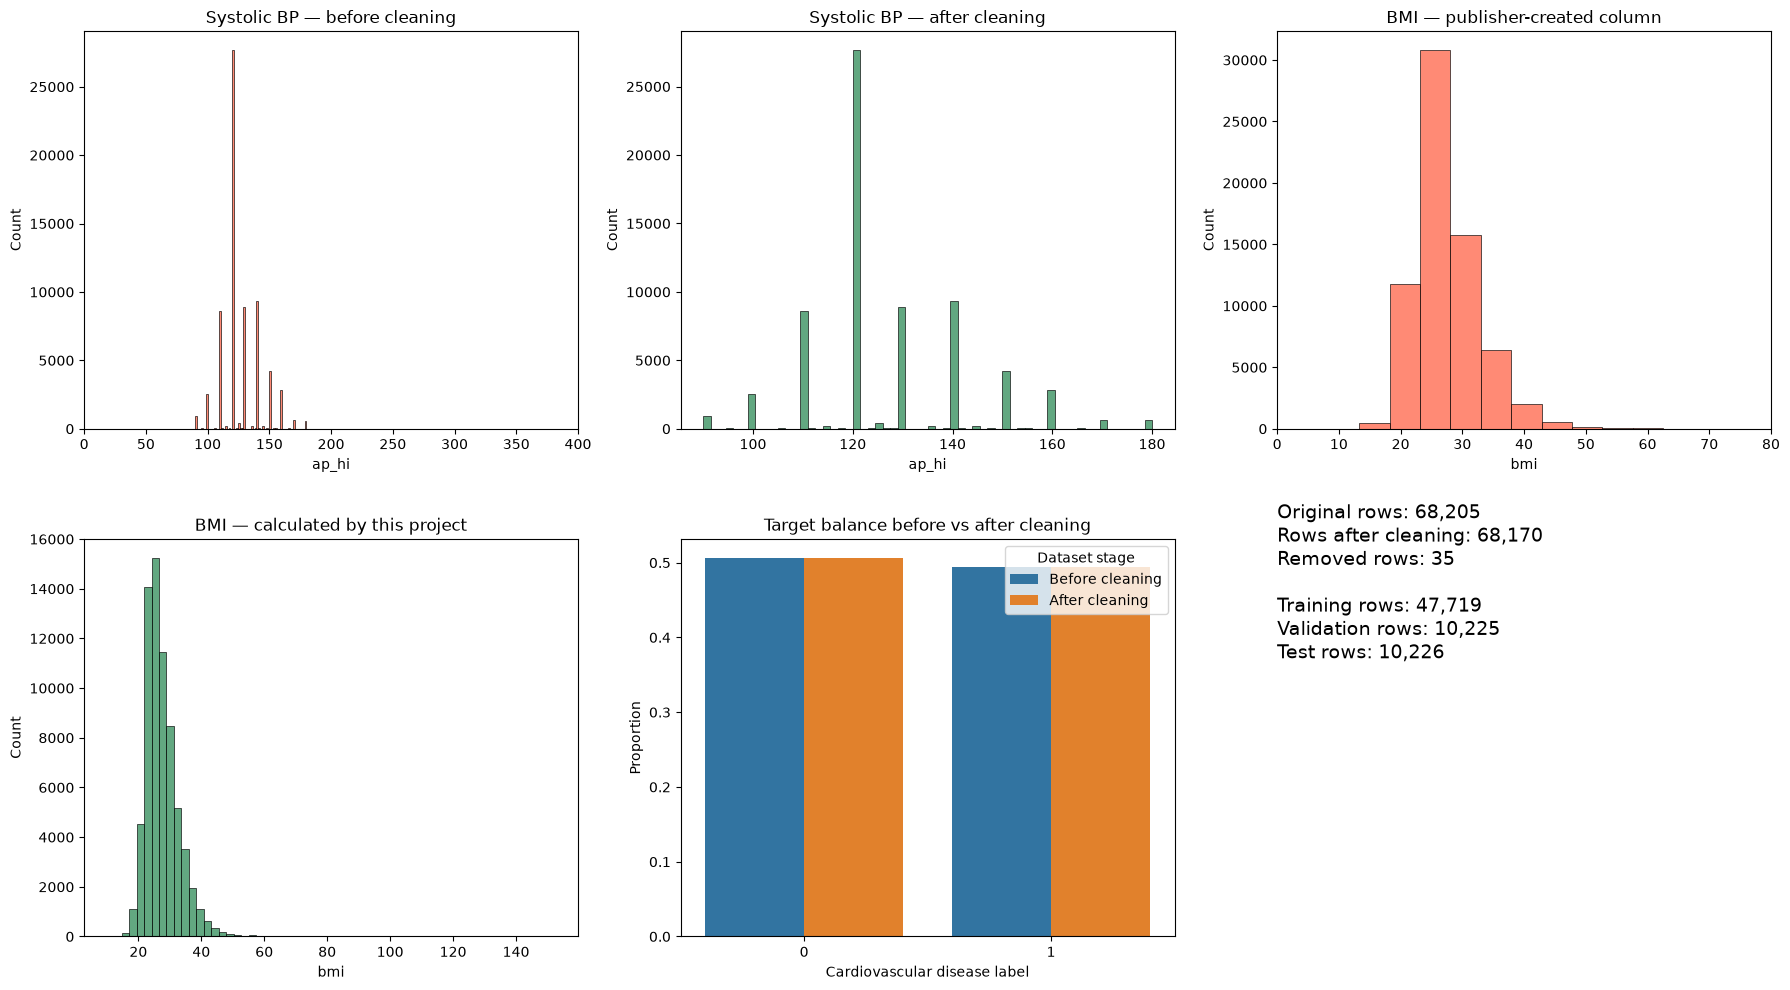

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.histplot(raw_data["ap_hi"], bins=60, ax=axes[0, 0], color="tomato")
axes[0, 0].set_title("Systolic BP — before cleaning")
axes[0, 0].set_xlim(0, 400)

sns.histplot(cleaned_data["ap_hi"], bins=60, ax=axes[0, 1], color="seagreen")
axes[0, 1].set_title("Systolic BP — after cleaning")

sns.histplot(raw_data["bmi"], bins=60, ax=axes[0, 2], color="tomato")
axes[0, 2].set_title("BMI — publisher-created column")
axes[0, 2].set_xlim(0, 80)

sns.histplot(model_data["bmi"], bins=60, ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("BMI — calculated by this project")

class_balance = pd.DataFrame(
    {
        "Before cleaning": before_cleaning[TARGET_COLUMN].value_counts(normalize=True),
        "After cleaning": model_data[TARGET_COLUMN].value_counts(normalize=True),
    }
).reset_index()

class_balance = class_balance.melt(
    id_vars=TARGET_COLUMN,
    var_name="Dataset stage",
    value_name="Proportion",
)

sns.barplot(
    data=class_balance,
    x=TARGET_COLUMN,
    y="Proportion",
    hue="Dataset stage",
    ax=axes[1, 1],
)
axes[1, 1].set_title("Target balance before vs after cleaning")
axes[1, 1].set_xlabel("Cardiovascular disease label")

axes[1, 2].axis("off")
axes[1, 2].text(
    0,
    0.7,
    f"Original rows: {len(raw_data):,}\n"
    f"Rows after cleaning: {len(model_data):,}\n"
    f"Removed rows: {len(raw_data) - len(model_data):,}\n\n"
    f"Training rows: {len(train_data):,}\n"
    f"Validation rows: {len(validation_data):,}\n"
    f"Test rows: {len(test_data):,}",
    fontsize=14,
)

plt.tight_layout()
plt.show()

### Preprocessing conclusion

The original cardiovascular dataset contained 68,205 records. After applying clinical plausibility checks, 68,170 valid records remained; only 35 records (0.05%) were removed. The binary target distribution remained nearly balanced after cleaning.

Original publisher-derived fields were excluded. Age in years, body-mass index, and binary sex representation were independently engineered from the original measurements. A stratified 70/15/15 training, validation, and test split was created. Continuous features were standardized using parameters fitted only on the training set to prevent data leakage.